# Brachistochrone Wigner Snapshots: State Prep and Logical Transfer

Two time-optimal (quantum brachistochrone) trajectories in one figure, following Carlini et al., *Phys. Rev. Lett.* **96**, 060503 (2006):

1. **State preparation:** $\ket{0} \to \ket{0_L}$
2. **Logical transfer:** $\ket{0_L} \to \ket{1_L}$

Each row shows Wigner snapshots at evenly spaced fractions $t/T^*$ of that trajectory's own minimum time $T^* = \theta_B / \lVert H \rVert$. All panels share one diverging color scale so negativity is directly comparable across rows.

## Imports

In [46]:
%load_ext autoreload
%autoreload 2

import os

import matplotlib.colors as mpl_colors
import matplotlib.pyplot as plt
import numpy as np

import jax.numpy as jnp
import jaxquantum as jqt

from gkp_optimal_control.brachistochrone import quantum_brachistochrone_hamiltonian
from gkp_optimal_control.plotting import set_plot_style
from gkp_optimal_control.states import coherent_state_vectors, fock_state, gkp_states
from gkp_optimal_control.utils import compute_wigner, to_ket, to_qarray, wigner_trajectory

set_plot_style()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## System parameters

Same square-lattice code as `brachistochrone_gkp_state_prep.ipynb`: $\alpha = \sqrt{\pi/2}$, $\beta = i\sqrt{\pi/2}$, envelope $\Delta = 0.3$, and spectral-norm bound $\lVert H \rVert = 1$.

In [52]:
n_fock = 80
gkp_delta = 0.3
gkp_cutoff = 10
gkp_alpha = jnp.sqrt(jnp.pi / 2)
gkp_beta = jnp.sqrt(jnp.pi / 2) * 1j

coherent_state = jnp.squeeze(coherent_state_vectors(n_fock, jnp.array([gkp_alpha])))

energy_bound = 1.0
n_steps = 500

# Wigner / figure settings
x_bound = 5.0
y_bound = 5.0
grid_points = 200
n_snapshots = 5

fig_dir = "../../figs/brachistochrone"
fig_name = "brachistochrone_wigner_snapshots_vac_to_0L_and_0L_to_1L.pdf"

vac = fock_state(n_fock, 0)
gkp_0, gkp_1 = gkp_states(n_fock, gkp_alpha, gkp_beta, gkp_delta, gkp_cutoff)

print(f"Effective GKP squeezing: {float(-10 * jnp.log10(gkp_delta**2)):.2f} dB")
print(f"|<0_L|1_L>| = {float(jnp.abs(jnp.vdot(to_ket(gkp_0), to_ket(gkp_1)))):.2e}")

Effective GKP squeezing: 10.46 dB
|<0_L|1_L>| = 3.17e-04


## Time-optimal trajectories

For each (initial, target) pair we build the brachistochrone Hamiltonian, evolve under it for exactly $T^*$ with `jqt.sesolve`, and check the final fidelity $|\braket{\psi_f | \psi(T^*)}|^2$.

$\ket{0_L}$ and $\ket{1_L}$ are nearly orthogonal, so the second transfer has $\theta_B \approx \pi/2$. The overlap phase $\varphi$ is then numerical noise, but it only sets the global phase of the final state, so the fidelity check is the right test.

In [53]:
transfers = {
    "prep": dict(
        psi_i=vac,
        psi_f=coherent_state,
        label=r"$\ket{0} \to \ket{0_L}$",
    ),
    "transfer": dict(
        psi_i=gkp_0,
        psi_f=gkp_1,
        label=r"$\ket{0_L} \to \ket{1_L}$",
    ),
}

for key, tr in transfers.items():
    ket_i = to_ket(tr["psi_i"])
    ket_f = to_ket(tr["psi_f"])

    h_optimal, min_time = quantum_brachistochrone_hamiltonian(
        ket_i, ket_f, energy_bound=energy_bound
    )

    tlist = jnp.linspace(0.0, float(min_time), n_steps)
    result = jqt.sesolve(to_qarray(h_optimal), to_qarray(tr["psi_i"]), tlist)

    # Batch of kets, shape (n_steps, n_fock, 1)
    states = jnp.asarray(result.data)
    fidelity = float(jnp.abs(jnp.vdot(ket_f, to_ket(states[-1]))) ** 2)

    tr.update(tlist=tlist, states=states, min_time=float(min_time), fidelity=fidelity)
    print(f"{key:>9}: T* = {float(min_time):.4f}   F(T*) = {fidelity:.8f}")

100% |██████████████████████████████████████████████| [00:00<00:00, 14169.95%/s]


     prep: T* = 1.0974   F(T*) = 1.00000000


100% |██████████████████████████████████████████████| [00:00<00:00, 21418.09%/s]

 transfer: T* = 1.5705   F(T*) = 1.00000000


## Two-row snapshot figure

`plot_wigner_snapshots` builds its own single-row figure, so this helper reproduces its rendering conventions (snapshot indexing, `RdBu_r` with a `TwoSlopeNorm` centered at zero, Gouraud shading, rasterized meshes) on a shared $2 \times n$ grid with one colorbar spanning both rows.

The color scale follows the original convention: it is normalized to the peak $|W|$ of the target states. The vacuum peak ($1/\pi$) may exceed that and saturate in the first panel. Set `scale_to = "all"` to normalize over every plotted frame instead.

In [54]:
def snapshot_indices(n_states: int, n_snapshots: int) -> tuple[np.ndarray, list[int]]:
    # Same index rule as plot_wigner_snapshots: ceil of evenly spaced fractions.
    fracs = np.linspace(0.0, 1.0, n_snapshots)
    idx = [int(np.ceil(f * (n_states - 1))) for f in fracs]
    return fracs, idx


def plot_wigner_snapshot_rows(
    rows: list[dict],
    x_bound: float,
    y_bound: float,
    grid_points: int = 200,
    n_snapshots: int = 5,
    scale_to: str = "targets",  # "targets" (plot_wigner_snapshots convention) or "all"
    title: str | None = None,
):
    # Compute only the snapshot frames, not the full trajectory.
    row_frames = []
    for row in rows:
        fracs, idx = snapshot_indices(row["states"].shape[0], n_snapshots)
        x, y, frames = wigner_trajectory(row["states"][jnp.array(idx)], x_bound, y_bound, grid_points)
        row_frames.append(frames)

    # Shared symmetric color scale
    if scale_to == "targets":
        wmax = max(
            float(np.abs(compute_wigner(row["psi_f"], x_bound, y_bound, grid_points)[2]).max())
            for row in rows
        )
    elif scale_to == "all":
        wmax = max(float(np.abs(f).max()) for f in row_frames)
    else:
        raise ValueError("scale_to must be 'targets' or 'all'.")
    norm = mpl_colors.TwoSlopeNorm(vmin=-wmax, vcenter=0.0, vmax=wmax)

    n_rows = len(rows)
    fig = plt.figure(figsize=(14, 3.6 * n_rows), constrained_layout=True)
    gs = fig.add_gridspec(n_rows, n_snapshots + 1, width_ratios=[1] * n_snapshots + [0.07])
    axes = np.empty((n_rows, n_snapshots), dtype=object)

    xticks = np.linspace(-x_bound, x_bound, 5)
    yticks = np.linspace(-y_bound, y_bound, 5)

    mesh = None
    for r, (row, frames) in enumerate(zip(rows, row_frames)):
        for c, frac in enumerate(fracs):
            ax = fig.add_subplot(gs[r, c])
            axes[r, c] = ax
            mesh = ax.pcolormesh(
                x, y, frames[c],
                cmap="RdBu_r", norm=norm,
                shading="gouraud", rasterized=True,
            )
            ax.set_aspect("equal")
            ax.set_xticks(xticks)
            ax.set_yticks(yticks)

            if r == n_rows - 1:
                ax.set_xlabel(r"$q$")
            else:
                ax.set_xticklabels([])

            if r == 0:
                ax.set_title(rf"$t/T^* = {frac:.2f}$")

            if c == 0:
                ax.set_ylabel(r"$p$")
            else:
                ax.set_yticklabels([])

    fig.canvas.draw()
    fig.set_layout_engine("none")
    top = axes[0, -1].get_position()
    bottom = axes[-1, -1].get_position()
    cax = fig.add_axes([top.x1 + 0.012, bottom.y0, 0.015, top.y1 - bottom.y0])
    cbar = fig.colorbar(mesh, cax=cax)
    cbar.set_label(r"$W(q, p)$")

    if title:
        fig.suptitle(title)

    return fig, axes

Saved to ../../figs/brachistochrone/brachistochrone_wigner_snapshots_vac_to_0L_and_0L_to_1L.pdf


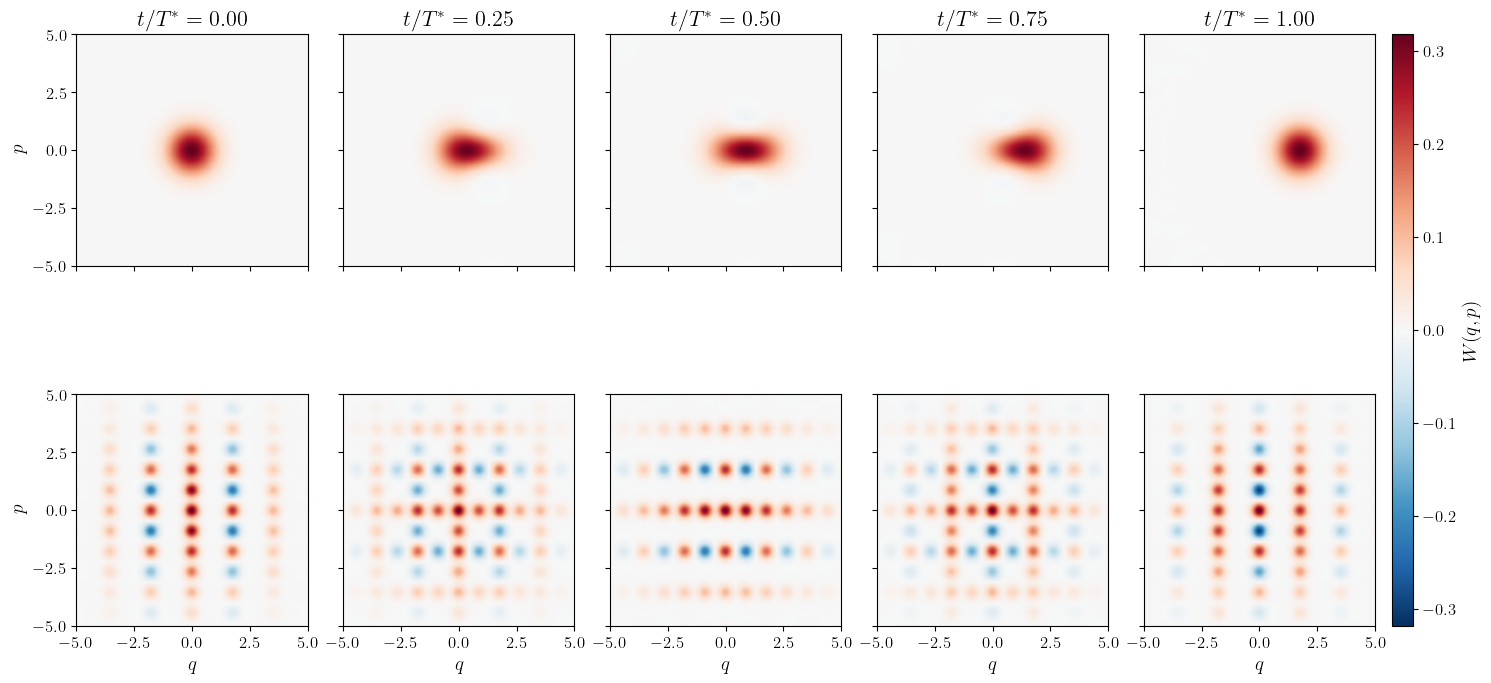

In [55]:
fig, axes = plot_wigner_snapshot_rows(
    rows=[transfers["prep"], transfers["transfer"]],
    x_bound=x_bound,
    y_bound=y_bound,
    grid_points=grid_points,
    n_snapshots=n_snapshots,
    scale_to="targets",
)

os.makedirs(fig_dir, exist_ok=True)
save_path = os.path.join(fig_dir, fig_name)
fig.savefig(save_path, bbox_inches="tight", dpi=300)
print(f"Saved to {save_path}")
plt.show()